<a href="https://colab.research.google.com/github/nabipay/ExtraaLearn/blob/main/ExtraaLearn.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# ExtraaLearn Project

## Context

The EdTech industry has been surging in the past decade immensely, and according to a forecast, the Online Education market would be worth $286.62bn by 2023 with a compound annual growth rate (CAGR) of 10.26% from 2018 to 2023. The modern era of online education has enforced a lot in its growth and expansion beyond any limit. Due to having many dominant features like ease of information sharing, personalized learning experience, transparency of assessment, etc, it is now preferable to traditional education.

In the present scenario due to the Covid-19, the online education sector has witnessed rapid growth and is attracting a lot of new customers. Due to this rapid growth, many new companies have emerged in this industry. With the availability and ease of use of digital marketing resources, companies can reach out to a wider audience with their offerings. The customers who show interest in these offerings are termed as leads. There are various sources of obtaining leads for Edtech companies, like

* The customer interacts with the marketing front on social media or other online platforms.
* The customer browses the website/app and downloads the brochure
* The customer connects through emails for more information.

The company then nurtures these leads and tries to convert them to paid customers. For this, the representative from the organization connects with the lead on call or through email to share further details.

## Objective

ExtraaLearn is an initial stage startup that offers programs on cutting-edge technologies to students and professionals to help them upskill/reskill. With a large number of leads being generated on a regular basis, one of the issues faced by ExtraaLearn is to identify which of the leads are more likely to convert so that they can allocate resources accordingly. You, as a data scientist at ExtraaLearn, have been provided the leads data to:
* Analyze and build an ML model to help identify which leads are more likely to convert to paid customers,
* Find the factors driving the lead conversion process
* Create a profile of the leads which are likely to convert


## Data Description

The data contains the different attributes of leads and their interaction details with ExtraaLearn. The detailed data dictionary is given below.


**Data Dictionary**
* ID: ID of the lead
* age: Age of the lead
* current_occupation: Current occupation of the lead. Values include 'Professional','Unemployed',and 'Student'
* first_interaction: How did the lead first interacted with ExtraaLearn. Values include 'Website', 'Mobile App'
* profile_completed: What percentage of profile has been filled by the lead on the website/mobile app. Values include Low - (0-50%), Medium - (50-75%), High (75-100%)
* website_visits: How many times has a lead visited the website
* time_spent_on_website: Total time spent on the website
* page_views_per_visit: Average number of pages on the website viewed during the visits.
* last_activity: Last interaction between the lead and ExtraaLearn.
    * Email Activity: Seeking for details about program through email, Representative shared information with lead like brochure of program , etc
    * Phone Activity: Had a Phone Conversation with representative, Had conversation over SMS with representative, etc
    * Website Activity: Interacted on live chat with representative, Updated profile on website, etc

* print_media_type1: Flag indicating whether the lead had seen the ad of ExtraaLearn in the Newspaper.
* print_media_type2: Flag indicating whether the lead had seen the ad of ExtraaLearn in the Magazine.
* digital_media: Flag indicating whether the lead had seen the ad of ExtraaLearn on the digital platforms.
* educational_channels: Flag indicating whether the lead had heard about ExtraaLearn in the education channels like online forums, discussion threads, educational websites, etc.
* referral: Flag indicating whether the lead had heard about ExtraaLearn through reference.
* status: Flag indicating whether the lead was converted to a paid customer or not.

In [61]:
# Import necessaey libraries
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import warnings
warnings.filterwarnings('ignore')

In [62]:

# Download latest utility library from GitHub
!wget -q -O ml_utils.py https://raw.githubusercontent.com/nabipay/python-ml-utilities/main/ml_utils.py


import importlib
import ml_utils
importlib.reload(ml_utils)

# Import custom functions
from ml_utils import histogram_boxplot, chk_outliers, stacked_barplot

# **Import Data**

In [63]:
# Import Data
data = pd.read_csv("https://raw.githubusercontent.com/nabipay/ExtraaLearn/main/ExtraaLearn.csv")

In [64]:
# First look at the data
data.head(4)

,ID,age,current_occupation,first_interaction,profile_completed,website_visits,time_spent_on_website,page_views_per_visit,last_activity,print_media_type1,print_media_type2,digital_media,educational_channels,referral,status
0,EXT001,57,Unemployed,Website,High,7,1639,1.861,Website Activity,Yes,No,Yes,No,No,1
1,EXT002,56,Professional,Mobile App,Medium,2,83,0.320,Website Activity,No,No,No,Yes,No,0
2,EXT003,52,Professional,Website,Medium,3,330,0.074,Website Activity,No,No,Yes,No,No,0
3,EXT004,53,Unemployed,Website,High,4,464,2.057,Website Activity,No,No,No,No,No,1


In [65]:
data.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 4612 entries, 0 to 4611
Data columns (total 15 columns):
 #   Column                 Non-Null Count  Dtype  
---  ------                 --------------  -----  
 0   ID                     4612 non-null   object 
 1   age                    4612 non-null   int64  
 2   current_occupation     4612 non-null   object 
 3   first_interaction      4612 non-null   object 
 4   profile_completed      4612 non-null   object 
 5   website_visits         4612 non-null   int64  
 6   time_spent_on_website  4612 non-null   int64  
 7   page_views_per_visit   4612 non-null   float64
 8   last_activity          4612 non-null   object 
 9   print_media_type1      4612 non-null   object 
 10  print_media_type2      4612 non-null   object 
 11  digital_media          4612 non-null   object 
 12  educational_channels   4612 non-null   object 
 13  referral               4612 non-null   object 
 14  status                 4612 non-null   int64  
dtypes: f

In [66]:
# convert dummy variables from object to numerical dummy variables
binary_cols = [
    'print_media_type1',
    'print_media_type2',
    'digital_media',
    'educational_channels',
    'referral'
]

data[binary_cols] = data[binary_cols].replace({'Yes': 1, 'No': 0}).astype(int)

In [67]:
data.sample(3)

,ID,age,current_occupation,first_interaction,profile_completed,website_visits,time_spent_on_website,page_views_per_visit,last_activity,print_media_type1,print_media_type2,digital_media,educational_channels,referral,status
3225,EXT3226,56,Professional,Website,High,2,235,1.964,Phone Activity,0,0,0,0,0,1
1031,EXT1032,56,Professional,Website,Medium,1,158,2.203,Website Activity,0,0,0,0,0,0
3962,EXT3963,30,Professional,Website,High,4,64,4.303,Email Activity,0,0,0,1,0,1


In [68]:
data[binary_cols].isna().sum()

,0
print_media_type1,0
print_media_type2,0
digital_media,0
educational_channels,0
referral,0


In [69]:
# Check for missing values

data.isnull().sum()

,0
ID,0
age,0
current_occupation,0
first_interaction,0
profile_completed,0
website_visits,0
time_spent_on_website,0
page_views_per_visit,0
last_activity,0
print_media_type1,0


**Observation:**

It apears that none of columns contains
missing values.

In [70]:
data.sample(4)

,ID,age,current_occupation,first_interaction,profile_completed,website_visits,time_spent_on_website,page_views_per_visit,last_activity,print_media_type1,print_media_type2,digital_media,educational_channels,referral,status
4439,EXT4440,61,Unemployed,Website,Medium,0,0,0.000,Email Activity,0,0,0,0,0,0
2538,EXT2539,60,Professional,Mobile App,High,5,1958,2.783,Email Activity,1,0,0,0,1,1
3450,EXT3451,60,Professional,Mobile App,Medium,3,85,2.339,Email Activity,0,0,0,0,0,0
1672,EXT1673,31,Professional,Mobile App,Low,15,1,3.872,Phone Activity,0,0,0,0,0,0


In [71]:
# Seperate numerical columns
numeric_data = data.select_dtypes(include='number')
numeric_data.columns

Index(['age', 'website_visits', 'time_spent_on_website',
       'page_views_per_visit', 'print_media_type1', 'print_media_type2',
       'digital_media', 'educational_channels', 'referral', 'status'],
      dtype='object')

In [72]:
data.shape

(4612, 15)

In [73]:
data.describe()

,age,website_visits,time_spent_on_website,page_views_per_visit,print_media_type1,print_media_type2,digital_media,educational_channels,referral,status
count,4612.000000,4612.000000,4612.000000,4612.000000,4612.000000,4612.00000,4612.000000,4612.000000,4612.000000,4612.000000
mean,46.201214,3.566782,724.011275,3.026126,0.107762,0.05052,0.114267,0.152862,0.020165,0.298569
std,13.161454,2.829134,743.828683,1.968125,0.310114,0.21904,0.318170,0.359894,0.140579,0.457680
min,18.000000,0.000000,0.000000,0.000000,0.000000,0.00000,0.000000,0.000000,0.000000,0.000000
25%,36.000000,2.000000,148.750000,2.077750,0.000000,0.00000,0.000000,0.000000,0.000000,0.000000
50%,51.000000,3.000000,376.000000,2.792000,0.000000,0.00000,0.000000,0.000000,0.000000,0.000000
75%,57.000000,5.000000,1336.750000,3.756250,0.000000,0.00000,0.000000,0.000000,0.000000,1.000000
max,63.000000,30.000000,2537.000000,18.434000,1.000000,1.00000,1.000000,1.000000,1.000000,1.000000


Some prileminary observations:
* There are total of 4612 observations.
* Average age of leads is 46 years, youngest lead is 18, and the oldest lead is 63 years old.
* Maximum website visits is 30 with average of about 4 visits accross all the leads.


# **Univariate Analysis**

## Univariate Analysis of numerical columns

In [74]:
# distinguish contimuous variables from dummy variables among numerical variables
continuous_cols = [
    'age',
    'website_visits',
    'time_spent_on_website',
    'page_views_per_visit'
]

data[continuous_cols].head(3)

,age,website_visits,time_spent_on_website,page_views_per_visit
0,57,7,1639,1.861
1,56,2,83,0.320
2,52,3,330,0.074


In [75]:
from ml_utils import histogram_boxplot, chk_outliers

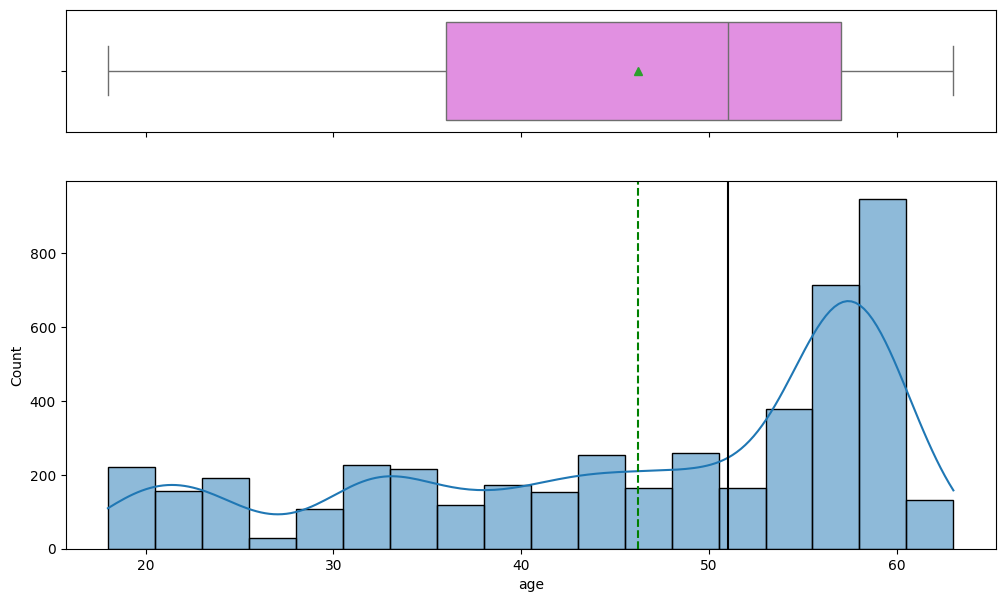

In [76]:
histogram_boxplot(data, 'age')

In [77]:
chk_outliers(data, 'age')

min 18
Lower range: 4.5
max 63
Upper range: 88.5


Observations:

* age is skewed to the left.
* there is no outlier

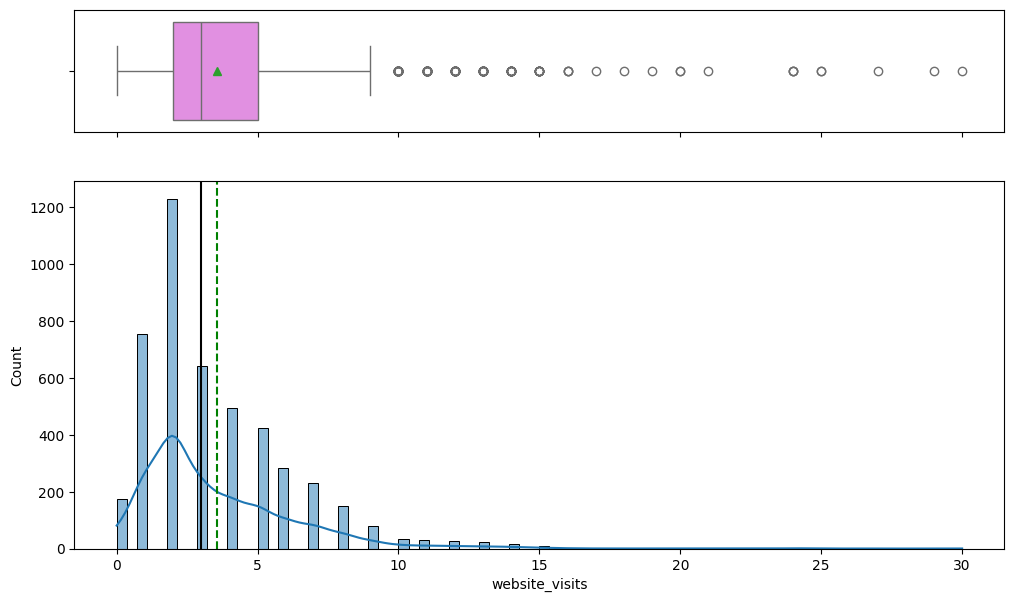

In [78]:
histogram_boxplot(data, 'website_visits')

In [79]:
chk_outliers(data, 'website_visits')

min 0
Lower range: -2.5
max 30
Upper range: 9.5
There are outliers above the upper range


The distribution of website visits is right-skewed, with potential outliers above 9.5 visits. These observations will be retained because they may represent highly engaged prospective customers.

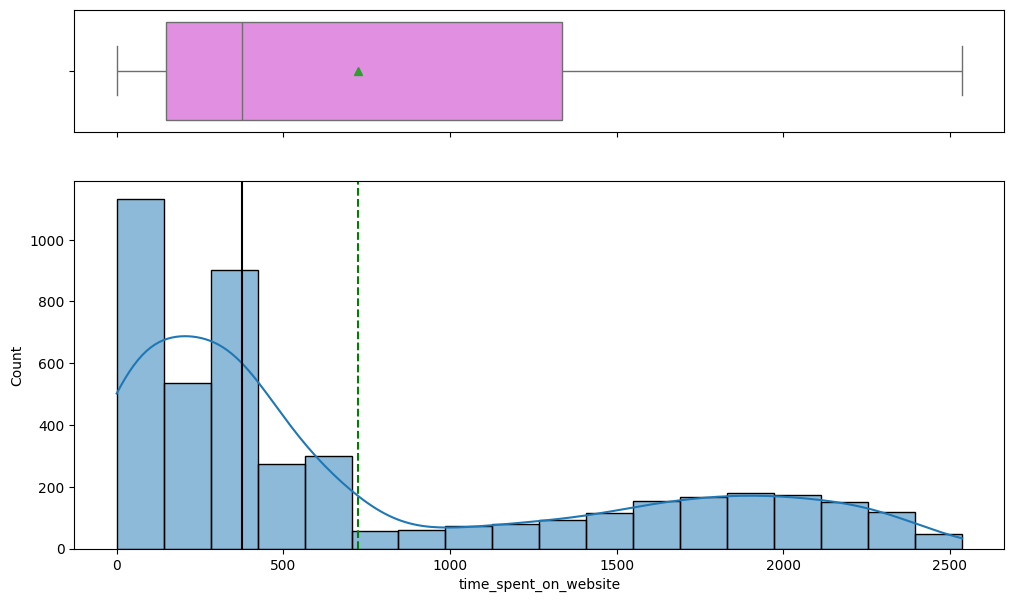

In [80]:
histogram_boxplot(data, 'time_spent_on_website')

In [81]:
chk_outliers(data, 'time_spent_on_website')

min 0
Lower range: -1633.25
max 2537
Upper range: 3118.75


The distribution of time_spent_on_website is bimodal and skewed to the right. There is outlier.

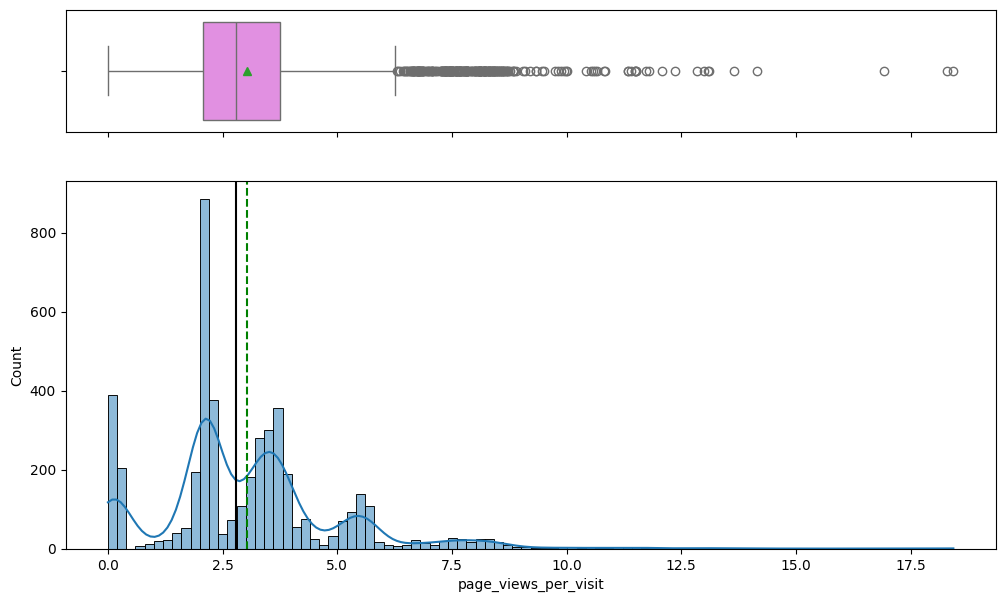

In [82]:
histogram_boxplot(data, 'page_views_per_visit')

In [83]:
chk_outliers(data, 'page_views_per_visit')

min 0.0
Lower range: -0.4399999999999995
max 18.434
Upper range: 6.273999999999999
There are outliers above the upper range


The distribution of page_views_per_visit is multi-modal and right skewed. Everything above 6.27 is flagged as outliers. We will keep them as could be leads who have visited large number of pages.

In [84]:
# check observation that are flagged as outliers in oage_views_per_visit
data['page_views_outliers'] = data['page_views_per_visit'] > 6.27

In [85]:
data.groupby('page_views_outliers')['status'].agg(['count', 'mean'])

,count,mean
page_views_outliers,,
False,4355,0.301722
True,257,0.245136


Leads who view an unusually high number of pages per visit are actually less likely to convert, by approximately 5.66 percentage points.

## Univariate analysis of categorical columns


In [86]:
data.select_dtypes(include=['object', 'category']).columns.tolist()

['ID',
 'current_occupation',
 'first_interaction',
 'profile_completed',
 'last_activity']

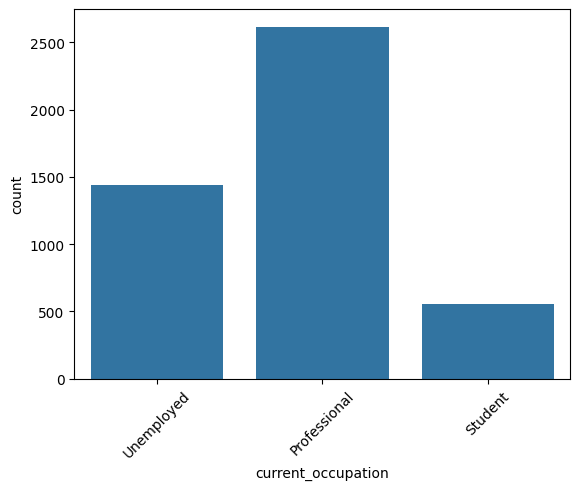

In [87]:
# count plot of current_occupation
sns.countplot(data=data, x='current_occupation')
plt.xticks(rotation=45)
plt.show()

More than 2500 leads are professionals. About 1500 unemployed and about 500 students.

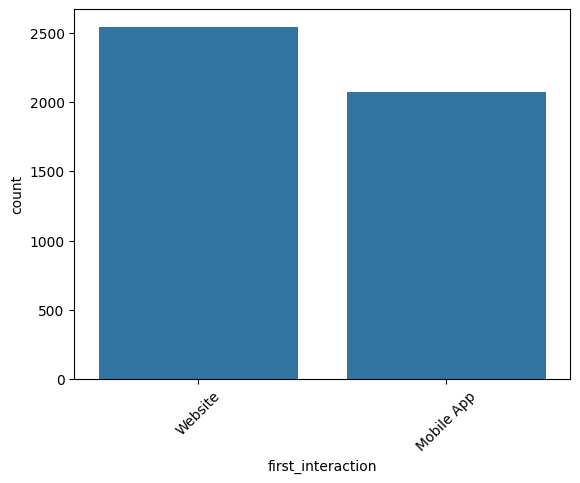

In [88]:
# count plot of first_interactions
sns.countplot(data=data, x= 'first_interaction')
plt.xticks(rotation=45)
plt.show()

About 2500 leads had their first interaction with the sight online through the site website, but a little more than 2000 have their first interactions through mobile app.

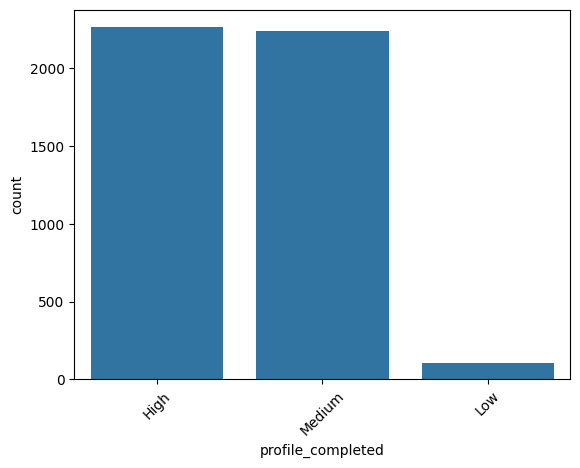

In [89]:
# count plot of profile_completed
sns.countplot(data=data, x= 'profile_completed')
plt.xticks(rotation=45)
plt.show()

More than 4000 leads completed most of their profiles.

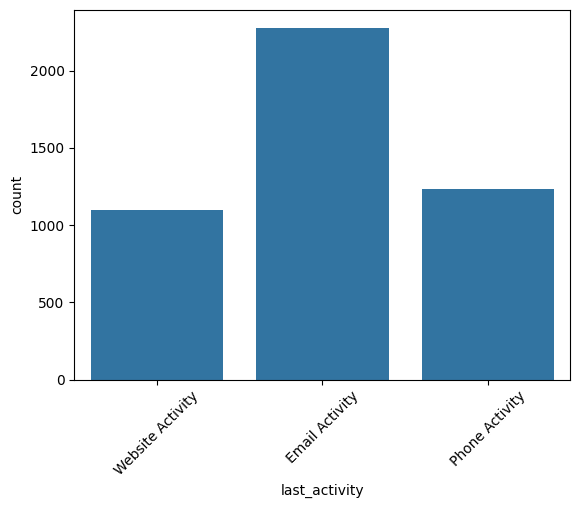

In [90]:
# count plot of last_activity
sns.countplot(data=data, x= 'last_activity')
plt.xticks(rotation=45)
plt.show()

Email activity was the last activity for most leads followed by phone activity. Only for a little bit more than 1000 leads the last activity was on the website.

# **Bivariate Analysis**

## Bivariate analysis of categorical columns aginst the target column

,count,conversion_rate
current_occupation,,
Professional,2616,35.51
Student,555,11.71
Unemployed,1441,26.58


------------------------------------------------------------------------------------------------------------------------


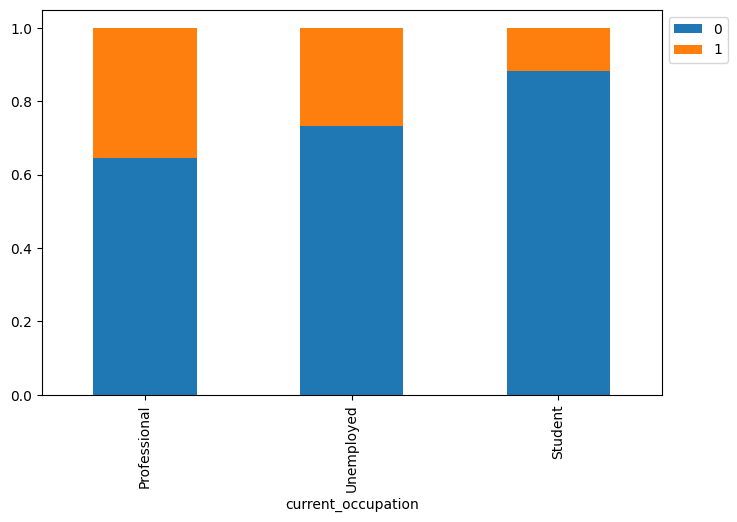

In [91]:
stacked_barplot(data, 'current_occupation', 'status')

Professionals have the highest conversion rate (35.51%), followed by unemployed leads (26.58%). Students have the lowest conversion rate (11.71%). This suggests that current occupation may be an important predictor of lead conversion.

,count,conversion_rate
first_interaction,,
Mobile App,2070,10.53
Website,2542,45.59


------------------------------------------------------------------------------------------------------------------------


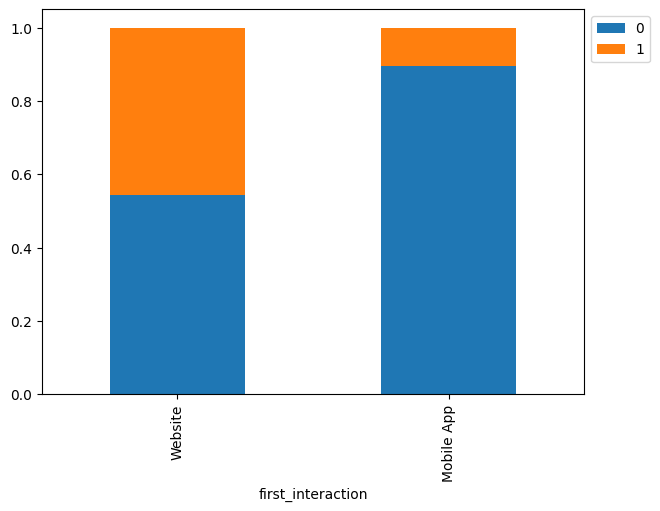

In [92]:
stacked_barplot(data, 'first_interaction', 'status')

Leads who had their first interaction throught the website have the highest conversion rate (46%), versus those who their first interaction was through mobile app whom their conversion rate was 11%.

,count,conversion_rate
profile_completed,,
High,2264,41.78
Low,107,7.48
Medium,2241,18.88


------------------------------------------------------------------------------------------------------------------------


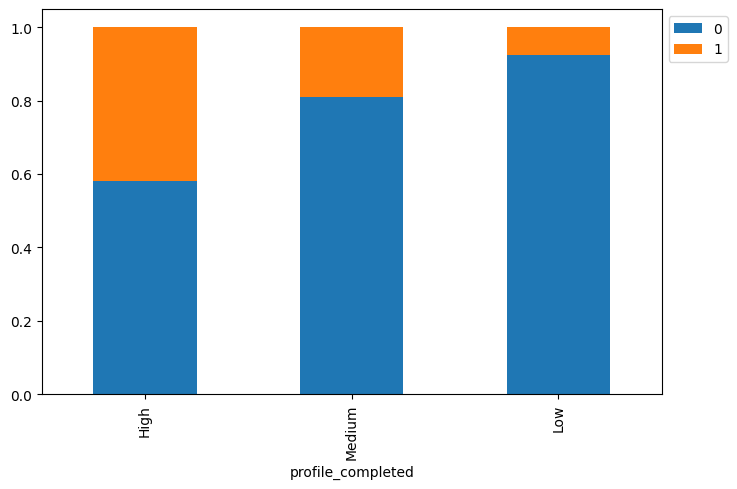

In [93]:
stacked_barplot(data, 'profile_completed', 'status')

Leads who completed their profile have the highest conversion rate (42%), followed by those who completed about half of their profile (19%). Leads who completed only a little bit of their profile have the lowest conversion rate (8%).

,count,conversion_rate
last_activity,,
Email Activity,2278,30.33
Phone Activity,1234,21.31
Website Activity,1100,38.45


------------------------------------------------------------------------------------------------------------------------


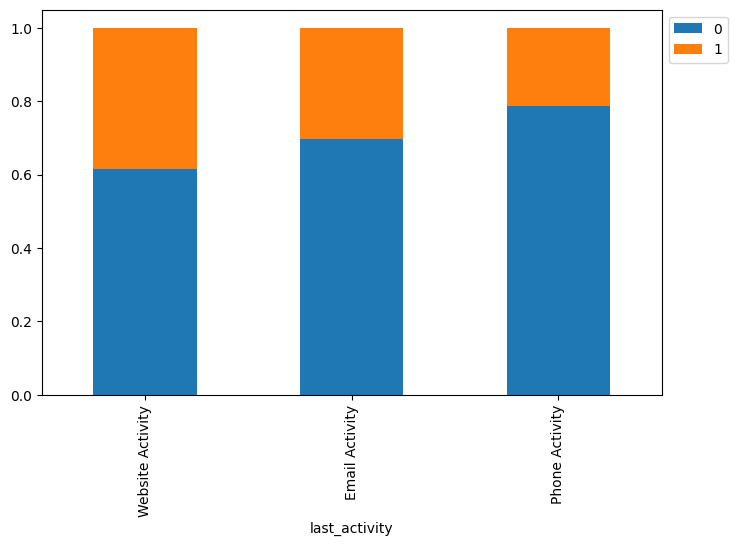

In [94]:
stacked_barplot(data, 'last_activity', 'status')


- Website activity has the highest conversion rate (38.45%), followed by email activity (30.33%).
- Phone activity has the lowest conversion rate (21.31%).
- Although email activity accounts for the largest number of leads (2,278), website activity is associated with the highest likelihood of conversion.
- This suggests that the type of last activity may be an important predictor of lead conversion.

## Bivariate analysis of dummy variables

In [95]:
# list of all dummy columns
dummy_cols = ['print_media_type1', 'print_media_type2',
              'digital_media', 'educational_channels', 'referral']

dummy_cols

['print_media_type1',
 'print_media_type2',
 'digital_media',
 'educational_channels',
 'referral']

,count,conversion_rate
print_media_type1,,
0,4115,29.60
1,497,31.99


------------------------------------------------------------------------------------------------------------------------


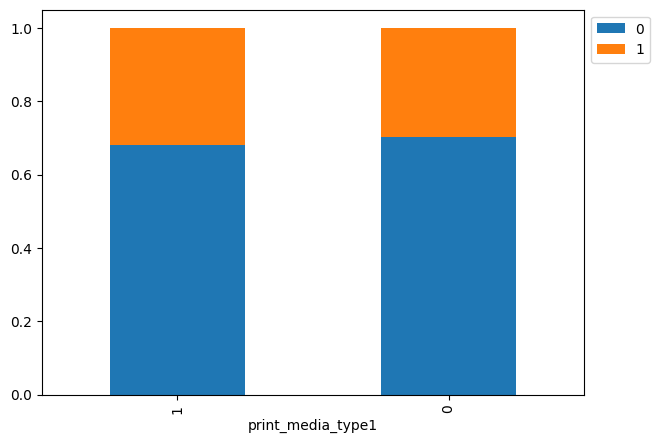

In [96]:
stacked_barplot(data, 'print_media_type1', 'status')

,count,conversion_rate
print_media_type2,,
0,4379,29.73
1,233,32.19


------------------------------------------------------------------------------------------------------------------------


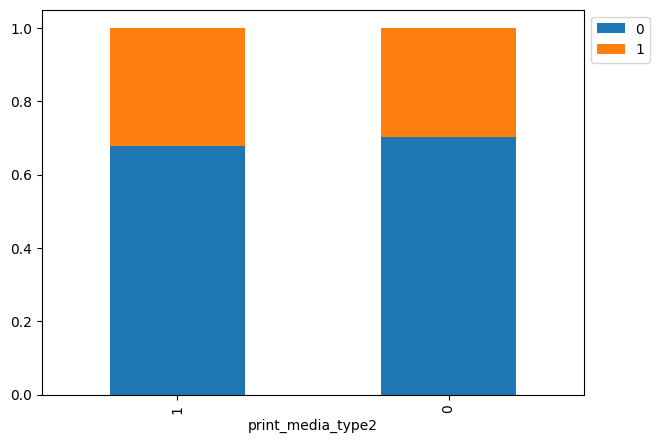

In [97]:
stacked_barplot(data, 'print_media_type2', 'status')

,count,conversion_rate
digital_media,,
0,4085,29.60
1,527,31.88


------------------------------------------------------------------------------------------------------------------------


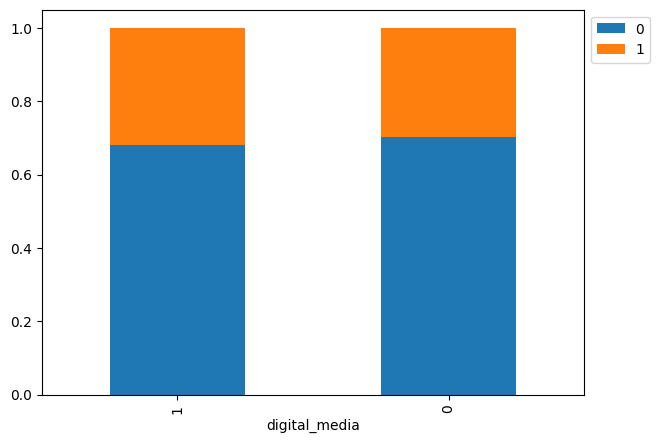

In [98]:
stacked_barplot(data, 'digital_media', 'status')

It does not seem that print_media_type1 or print_media_type2 or digital media have very meaningful impact on making leads to convert.

,count,conversion_rate
educational_channels,,
0,3907,30.20
1,705,27.94


------------------------------------------------------------------------------------------------------------------------


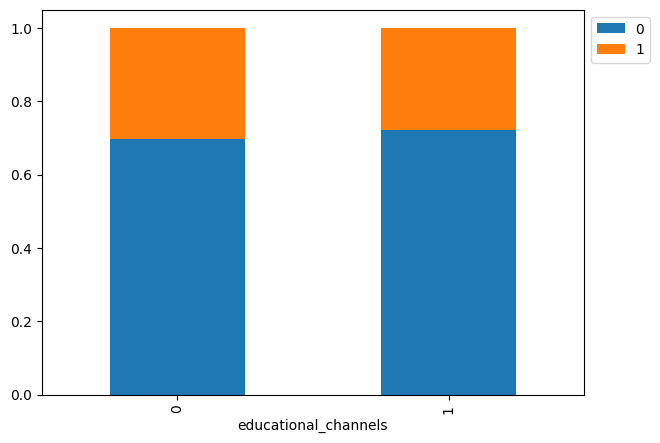

In [99]:
stacked_barplot(data, 'educational_channels', 'status')

Leads who learned about ExtaaLearn through educational channel have slight lower conversion rate (28%) followed by those who did not come through educational channel (30%).

,count,conversion_rate
referral,,
0,4519,29.08
1,93,67.74


------------------------------------------------------------------------------------------------------------------------


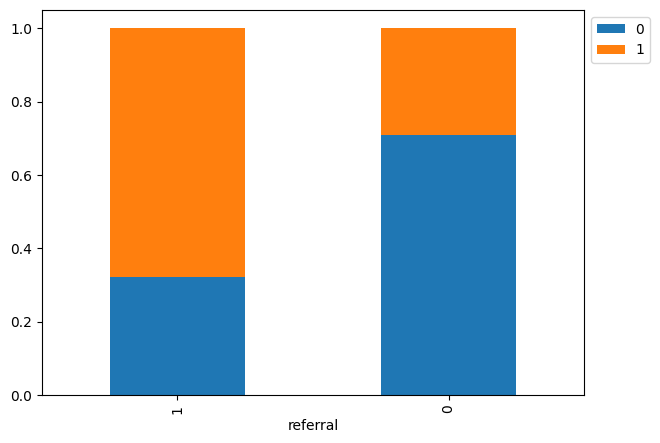

In [100]:
stacked_barplot(data, 'referral', 'status')

The results suggests that referral can have meaningful impact on conversion rate. Leads come through referral had 68% conversion rate.

## Bivariate Analysis of continuous variables

In [101]:
continuous_cols

['age', 'website_visits', 'time_spent_on_website', 'page_views_per_visit']

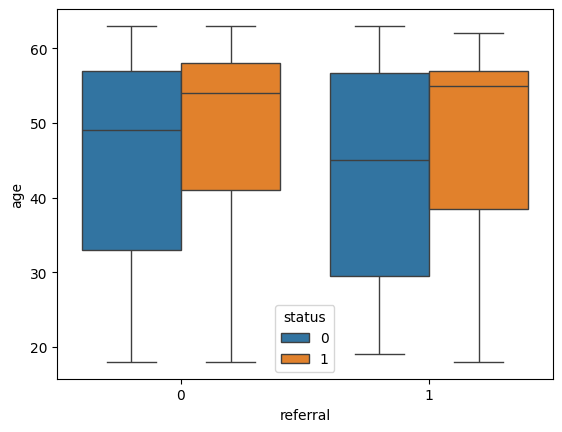

In [102]:
sns.boxplot(data=data, x="referral", y='age', hue='status')
plt.show()

**Observation:**
- Converted leads tend to be older than non-converted leads, regardless of referral status.
- Among non-referred leads, the median age is approximately 54 for converted leads versus 49 for non-converted leads.
- Among referred leads, the difference is more pronounced, with median ages of approximately 55 and 45, respectively.
- This suggests that age may be more strongly associated with conversion among referred leads. However, the distributions overlap considerably, so further analysis is needed to confirm this relationship.

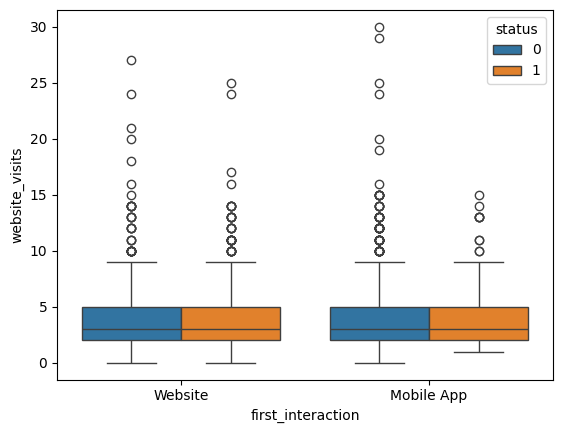

In [103]:
sns.boxplot(
    data=data,
    x='first_interaction',
    y='website_visits',
    hue='status'
)
plt.show()

Website visits don't appear to distinguish converted from non-converted leads very well, even when accounting for first interaction.

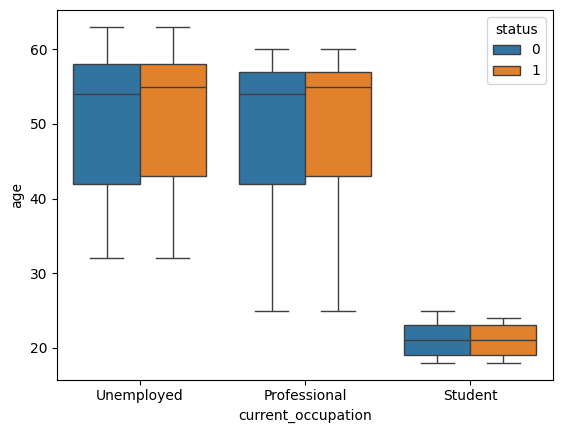

In [104]:
sns.boxplot(
    data=data,
    y='age',
    x='current_occupation',
    hue='status'
)
plt.show()

Students: Median age around 21, with very little variation.



Professionals: Median age around 54–55.



Unemployed: Median age around 54–55.



Conversion status: Within each occupation, the age distributions of converted and non-converted leads are remarkably similar.

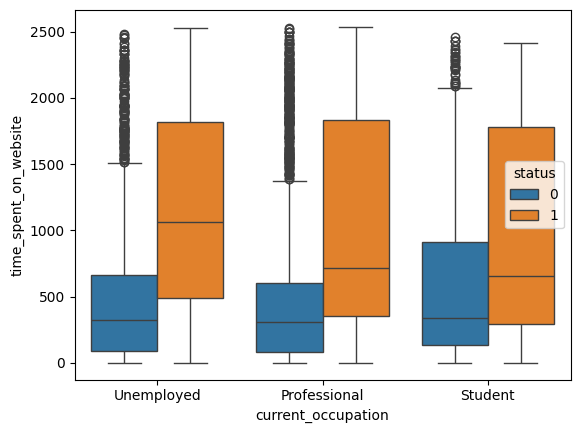

In [105]:
sns.boxplot(
    data=data,
    x='current_occupation',
    y='time_spent_on_website',
    hue='status'
)
plt.show()

The relationship between time spent on the website and conversion is quite striking.
- Unemployed: Converted leads spend substantially more time on the website (median approximately 1,050 versus 320).
- Professionals: Converted leads also spend more time (median approximately 720 versus 300).
- Students: The difference is smaller (approximately 650 versus 330), with considerable overlap between distributions.

Most importantly: The pattern holds across all three occupations. This suggests that time_spent_on_website may be a particularly useful predictor of conversion.

# **Classificaiton**

## Train / Test Split

In [106]:
X = data.drop(columns=['status', 'ID'])
y = data['status']

In [107]:
from sklearn.model_selection import train_test_split

X_train, X_test, y_train, y_test = train_test_split(
    X, y,
    test_size=0.2,
    random_state=42,
    stratify=y
)

## Encoding categorical columns


In [108]:
cat_cols = X_train.select_dtypes(include=['object', 'category']).columns

X_train = pd.get_dummies(X_train, columns=cat_cols, drop_first=True, dtype=int)
X_test = pd.get_dummies(X_test, columns=cat_cols, drop_first=True, dtype=int)

X_test = X_test.reindex(columns=X_train.columns, fill_value=0)

In [109]:
X_train.sample(3)

,age,website_visits,time_spent_on_website,page_views_per_visit,print_media_type1,print_media_type2,digital_media,educational_channels,referral,page_views_outliers,current_occupation_Student,current_occupation_Unemployed,first_interaction_Website,profile_completed_Low,profile_completed_Medium,last_activity_Phone Activity,last_activity_Website Activity
3427,30,1,376,2.137,0,0,0,1,0,False,0,0,0,0,1,1,0
3574,45,7,1441,3.842,0,0,0,0,0,False,0,1,0,0,1,0,0
1091,47,2,314,2.060,0,1,0,0,0,False,0,1,1,0,0,1,0


In [110]:
X_test.sample(3)

,age,website_visits,time_spent_on_website,page_views_per_visit,print_media_type1,print_media_type2,digital_media,educational_channels,referral,page_views_outliers,current_occupation_Student,current_occupation_Unemployed,first_interaction_Website,profile_completed_Low,profile_completed_Medium,last_activity_Phone Activity,last_activity_Website Activity
1693,54,2,346,1.951,0,0,0,0,0,False,0,0,0,0,1,0,0
1770,28,1,2274,0.260,0,0,0,0,0,False,0,0,1,0,0,0,0
3337,53,1,270,3.520,0,0,0,0,0,False,0,1,1,0,1,0,0


In [111]:
X_test.sample(3)

,age,website_visits,time_spent_on_website,page_views_per_visit,print_media_type1,print_media_type2,digital_media,educational_channels,referral,page_views_outliers,current_occupation_Student,current_occupation_Unemployed,first_interaction_Website,profile_completed_Low,profile_completed_Medium,last_activity_Phone Activity,last_activity_Website Activity
1829,41,3,2007,5.395,0,0,0,0,0,False,0,0,1,0,1,0,1
1011,22,1,343,1.563,0,0,0,0,0,False,1,0,0,0,0,0,1
2170,56,3,2113,3.561,0,0,0,0,0,False,0,0,0,0,0,1,0


## Scaling continous variables

In [112]:
# scaling continous columns on x_train and x_test
from sklearn.preprocessing import StandardScaler

scaler = StandardScaler()
scaler.fit(X_train[continuous_cols])

X_train[continuous_cols] = scaler.transform(X_train[continuous_cols])
X_test[continuous_cols] = scaler.transform(X_test[continuous_cols])

## Logistic Regression

In [113]:
from sklearn.linear_model import LogisticRegression

model_lr = LogisticRegression(max_iter=1000, random_state=42)

model_lr.fit(X_train, y_train)

LogisticRegression(max_iter=1000, random_state=42)

In [114]:
# Examine coefficient of our model
coefficients = pd.DataFrame({
    'Feature': X_train.columns,
    'Coefficient': model_lr.coef_[0]
})

coefficients.sort_values('Coefficient', ascending=False)

,Feature,Coefficient
12,first_interaction_Website,2.614989
8,referral,1.523134
2,time_spent_on_website,0.899351
16,last_activity_Website Activity,0.523995
5,print_media_type2,0.134155
7,educational_channels,0.126719
6,digital_media,0.101095
0,age,0.095378
4,print_media_type1,0.041738
3,page_views_per_visit,0.039918


### Observations — Logistic Regression Coefficients

- **First interaction through the website** has the strongest positive coefficient (+2.615), suggesting significantly higher odds of conversion compared with the mobile app.
- **Referral** also has a strong positive coefficient (+1.523), indicating that referred leads are more likely to convert.
- **Time spent on the website** has a positive coefficient (+0.899), consistent with our EDA findings that more engaged visitors tend to convert.
- **Students** have a strong negative coefficient (−1.756) relative to professionals, suggesting lower conversion odds.
- **Low and medium profile completion** have large negative coefficients (−1.812 and −1.595) relative to high completion, indicating that more complete profiles are associated with higher conversion odds.

**Overall:** The logistic regression results largely support our exploratory analysis. Website engagement, referrals, and profile completion appear to be important indicators of lead conversion. These relationships are associations, not necessarily causal effects.

### prediction of logistic model on test data

In [125]:
y_pred_lr = model_lr.predict(X_test)

In [126]:
pd.DataFrame({
    'Actual': y_test.values,
    'Predicted': y_pred_lr
}).head(10)

,Actual,Predicted
0,1,0
1,0,0
2,1,1
3,1,0
4,1,1
5,0,1
6,0,0
7,0,0
8,0,0
9,1,1


In [127]:
print("Actual conversion rate:", y_test.mean())
print("Predicted conversion rate:", y_pred_lr.mean())

Actual conversion rate: 0.2990249187432286
Predicted conversion rate: 0.26435536294691225


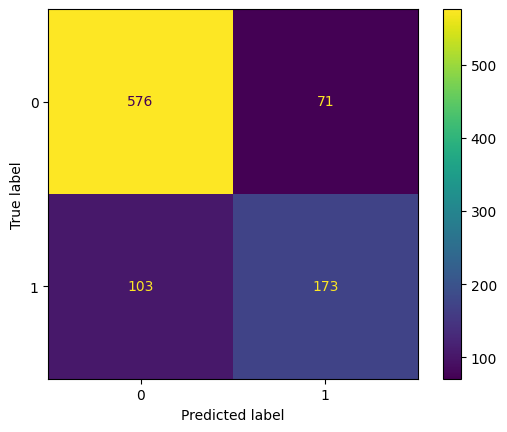

In [128]:
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay

cm = confusion_matrix(y_test, y_pred_lr)
ConfusionMatrixDisplay(cm).plot()

In [129]:
from sklearn.metrics import accuracy_score

accuracy = accuracy_score(y_test, y_pred_lr)
print(f"Model Accuracy: {accuracy:.2%}")

Model Accuracy: 81.15%


In [130]:
from sklearn.metrics import classification_report

print(classification_report(y_test, y_pred_lr))

              precision    recall  f1-score   support

           0       0.85      0.89      0.87       647
           1       0.71      0.63      0.67       276

    accuracy                           0.81       923
   macro avg       0.78      0.76      0.77       923
weighted avg       0.81      0.81      0.81       923



## Decision Tree

In [121]:
# create decision tree model
from sklearn.tree import DecisionTreeClassifier

model_dt = DecisionTreeClassifier(
    max_depth=5,
    random_state=42
)

# fit decision tree model to train data
model_dt.fit(X_train, y_train)

DecisionTreeClassifier(max_depth=5, random_state=42)

In [123]:
# prodict decision tree model on test data
y_pred_dt = model_dt.predict(X_test)

In [124]:
# accuracy of decisoin tree model
print(f"Decision Tree Accuracy: {accuracy_score(y_test, y_pred_dt):.2%}")
print(classification_report(y_test, y_pred_dt))

Decision Tree Accuracy: 85.59%
              precision    recall  f1-score   support

           0       0.91      0.89      0.90       647
           1       0.75      0.79      0.77       276

    accuracy                           0.86       923
   macro avg       0.83      0.84      0.83       923
weighted avg       0.86      0.86      0.86       923



In [131]:
# check the accuracy of model_dt on training data
print(f"Training accuracy: {model_dt.score(X_train, y_train):.2%}")
print(f"Test accuracy: {model_dt.score(X_test, y_test):.2%}")

Training accuracy: 86.39%
Test accuracy: 85.59%


## Random Forest

In [135]:
# create random froest mdoel
from sklearn.ensemble import RandomForestClassifier

model_rf = RandomForestClassifier(
    n_estimators=100,
    max_depth=10,
    random_state=42
)
# fit random forest model to training data
model_rf.fit(X_train, y_train)

RandomForestClassifier(max_depth=10, random_state=42)

In [136]:
# predict model on test data
y_pred_rf = model_rf.predict(X_test)

print(f"Random Forest Accuracy: {accuracy_score(y_test, y_pred_rf):.2%}")
print(classification_report(y_test, y_pred_rf))

Random Forest Accuracy: 87.32%
              precision    recall  f1-score   support

           0       0.90      0.93      0.91       647
           1       0.81      0.75      0.78       276

    accuracy                           0.87       923
   macro avg       0.85      0.84      0.85       923
weighted avg       0.87      0.87      0.87       923



In [137]:
# check if model under-fitting

print(f"Training accuracy: {model_rf.score(X_train, y_train):.2%}")
print(f"Test accuracy: {model_rf.score(X_test, y_test):.2%}")

Training accuracy: 91.92%
Test accuracy: 87.32%


## Gradient Boosting

In [138]:
# create gradient boosting model
from sklearn.ensemble import GradientBoostingClassifier

model_gb = GradientBoostingClassifier(
    n_estimators=100,
    learning_rate=0.1,
    max_depth=3,
    random_state=42
)
# fit gradient boosting model to train data
model_gb.fit(X_train, y_train)

GradientBoostingClassifier(random_state=42)

In [139]:
# Predict on test data
y_pred_gb = model_gb.predict(X_test)

# Evaluate performance
print(f"Gradient Boosting Accuracy: {accuracy_score(y_test, y_pred_gb):.2%}")
print(classification_report(y_test, y_pred_gb))

Gradient Boosting Accuracy: 86.67%
              precision    recall  f1-score   support

           0       0.90      0.91      0.91       647
           1       0.79      0.76      0.77       276

    accuracy                           0.87       923
   macro avg       0.84      0.84      0.84       923
weighted avg       0.87      0.87      0.87       923



## COmparision of Precision Accuracy and f1 Score of all four models

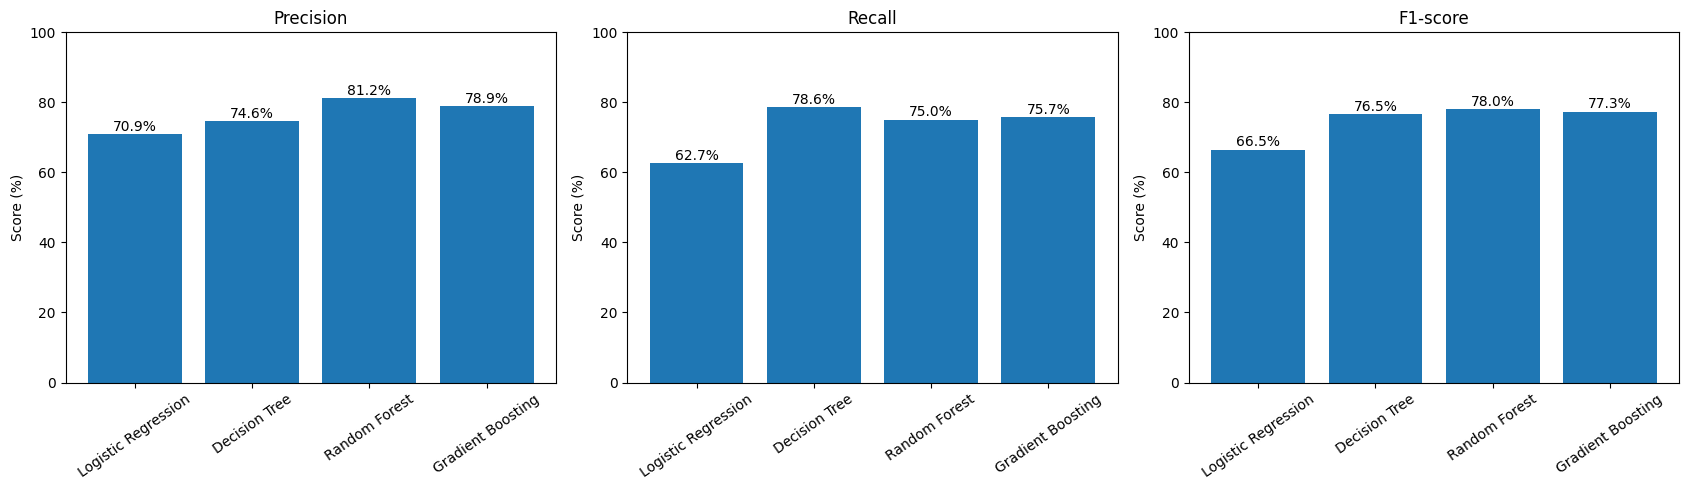

In [140]:
import matplotlib.pyplot as plt
from sklearn.metrics import precision_score, recall_score, f1_score

predictions = {
    "Logistic Regression": y_pred_lr,
    "Decision Tree": y_pred_dt,
    "Random Forest": y_pred_rf,
    "Gradient Boosting": y_pred_gb
}

metrics = {
    "Precision": precision_score,
    "Recall": recall_score,
    "F1-score": f1_score
}

fig, axes = plt.subplots(1, 3, figsize=(17, 5))

for ax, (metric_name, metric_func) in zip(axes, metrics.items()):
    scores = [
        metric_func(y_test, pred) * 100
        for pred in predictions.values()
    ]

    bars = ax.bar(predictions.keys(), scores)

    ax.set_title(metric_name)
    ax.set_ylabel("Score (%)")
    ax.set_ylim(0, 100)
    ax.tick_params(axis="x", rotation=35)

    for bar, score in zip(bars, scores):
        ax.text(
            bar.get_x() + bar.get_width() / 2,
            bar.get_height() + 1,
            f"{score:.1f}%",
            ha="center"
        )

plt.tight_layout()
plt.show()

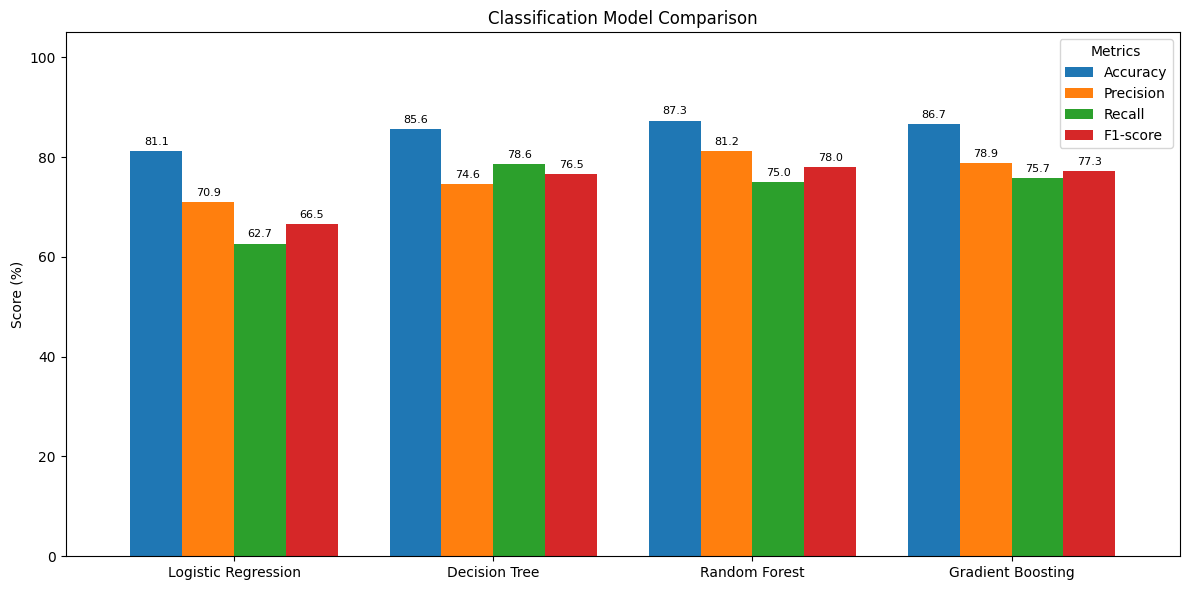

In [141]:
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.metrics import (
    accuracy_score, precision_score, recall_score, f1_score
)

predictions = {
    "Logistic Regression": y_pred_lr,
    "Decision Tree": y_pred_dt,
    "Random Forest": y_pred_rf,
    "Gradient Boosting": y_pred_gb
}

results = pd.DataFrame({
    name: {
        "Accuracy": accuracy_score(y_test, pred) * 100,
        "Precision": precision_score(y_test, pred) * 100,
        "Recall": recall_score(y_test, pred) * 100,
        "F1-score": f1_score(y_test, pred) * 100
    }
    for name, pred in predictions.items()
}).T

ax = results.plot(
    kind="bar",
    figsize=(12, 6),
    width=0.8
)

ax.set_title("Classification Model Comparison")
ax.set_ylabel("Score (%)")
ax.set_xlabel("")
ax.set_ylim(0, 105)
ax.tick_params(axis="x", rotation=0)
ax.legend(title="Metrics")

for container in ax.containers:
    ax.bar_label(container, fmt="%.1f", padding=3, fontsize=8)

plt.tight_layout()
plt.show()

# Cross Validation

## Cross Validation of Random Forest model

In [142]:
from sklearn.model_selection import cross_val_score

cv_scores = cross_val_score(
    model_rf,
    X_train,
    y_train,
    cv=5,
    scoring="accuracy"
)

print("CV accuracy scores:", cv_scores)
print(f"Mean CV accuracy: {cv_scores.mean():.2%}")

CV accuracy scores: [0.85636856 0.85907859 0.86585366 0.85365854 0.86567164]
Mean CV accuracy: 86.01%


## cross validation of Logist Regression

In [143]:
cv_scores_lr = cross_val_score(
    model_lr,
    X_train,
    y_train,
    cv=5,
    scoring="accuracy"
)

print("CV accuracy scores:", cv_scores_lr)
print(f"Mean CV accuracy: {cv_scores_lr.mean():.2%}")

CV accuracy scores: [0.79674797 0.82926829 0.82249322 0.80623306 0.82225237]
Mean CV accuracy: 81.54%


## cross validation of Decision Tree


In [144]:
cv_scores_dt = cross_val_score(
    model_dt,
    X_train,
    y_train,
    cv=5,
    scoring="accuracy"
)

print("CV accuracy scores:", cv_scores_dt)
print(f"Mean CV accuracy: {cv_scores_dt.mean():.2%}")

CV accuracy scores: [0.84688347 0.85772358 0.86585366 0.84281843 0.85617368]
Mean CV accuracy: 85.39%


## cross validation of Gradient Boosting

In [145]:
cv_scores_gb = cross_val_score(
    model_gb,
    X_train,
    y_train,
    cv=5,
    scoring="accuracy"
)

print("CV accuracy scores:", cv_scores_gb)
print(f"Mean CV accuracy: {cv_scores_gb.mean():.2%}")

CV accuracy scores: [0.85907859 0.86585366 0.86720867 0.8495935  0.86567164]
Mean CV accuracy: 86.15%


## Check all four models performance on five-fold cv for recall

In [146]:
models = {
    "Logistic Regression": model_lr,
    "Decision Tree": model_dt,
    "Random Forest": model_rf,
    "Gradient Boosting": model_gb
}

for name, model in models.items():
    scores = cross_val_score(
        model,
        X_train,
        y_train,
        cv=5,
        scoring="recall"
    )
    print(f"{name}: {scores.mean():.2%}")

Logistic Regression: 62.12%
Decision Tree: 76.74%
Random Forest: 71.57%
Gradient Boosting: 73.84%


## Check all four models performance on five-fold cv for recall

In [147]:
for name, model in models.items():
    scores = cross_val_score(
        model,
        X_train,
        y_train,
        cv=5,
        scoring="f1"
    )
    print(f"{name}: {scores.mean():.2%}")

Logistic Regression: 66.79%
Decision Tree: 75.81%
Random Forest: 75.32%
Gradient Boosting: 76.09%


### Model Evaluation — Summary and Next Steps

We trained and evaluated four classification models: Logistic Regression, Decision Tree, Random Forest, and Gradient Boosting. After comparing their performance on the test dataset using accuracy, precision, recall, and F1-score, we performed five-fold cross-validation to assess their consistency and generalization. **Gradient Boosting achieved the highest average cross-validation accuracy (86.15%) and F1-score (76.09%)**, while **Decision Tree achieved the highest recall (76.74%)**, making it particularly effective at identifying potential converters. Random Forest achieved the highest test accuracy (87.32%). Overall, Gradient Boosting and Decision Tree emerged as promising candidates depending on our business objective. **Next, we will perform hyperparameter tuning** to optimize model performance, followed by final model selection and interpretation of the most important predictive features.

# Hyperparameter tuning

We're goiing to test:
- 2 values for n_estimators
- 2 values for learning_rate
- 3 values for max_depth
That's \(2\times2\times3=12\) combinations, each evaluated across five folds: 60 model fits!

In [148]:
from sklearn.model_selection import GridSearchCV

param_grid_gb = {
    "n_estimators": [100, 200],
    "learning_rate": [0.05, 0.1],
    "max_depth": [2, 3, 4]
}

grid_gb = GridSearchCV(
    estimator=model_gb,
    param_grid=param_grid_gb,
    scoring="f1",
    cv=5,
    n_jobs=-1
)

grid_gb.fit(X_train, y_train)

GridSearchCV(cv=5, estimator=GradientBoostingClassifier(random_state=42),
             n_jobs=-1,
             param_grid={'learning_rate': [0.05, 0.1], 'max_depth': [2, 3, 4],
                         'n_estimators': [100, 200]},
             scoring='f1')

In [149]:
print("Best parameters:", grid_gb.best_params_)
print(f"Best CV F1-score: {grid_gb.best_score_:.2%}")

Best parameters: {'learning_rate': 0.1, 'max_depth': 3, 'n_estimators': 100}
Best CV F1-score: 76.09%


Hyper tuning did not make much of improvment. next hyper tuning decision tree model

In [151]:
# hyper tuning decision tree model
param_grid_dt = {
    "max_depth": [3, 5, 7, 10],
    "min_samples_split": [2, 5, 10],
    "min_samples_leaf": [1, 2, 5]
}

grid_dt = GridSearchCV(
    estimator=model_dt,
    param_grid=param_grid_dt,
    scoring="f1",
    cv=5,
    n_jobs=-1
)

grid_dt.fit(X_train, y_train)

print("Best parameters:", grid_dt.best_params_)
print(f"Best CV F1-score: {grid_dt.best_score_:.2%}")

Best parameters: {'max_depth': 5, 'min_samples_leaf': 1, 'min_samples_split': 2}
Best CV F1-score: 75.81%


### Hyperparameter Tuning — Summary

We performed hyperparameter tuning using GridSearchCV with five-fold cross-validation for both Gradient Boosting and Decision Tree models, optimizing the F1-score. Despite testing multiple parameter combinations, **neither model showed any improvement**. In both cases, GridSearchCV selected the original hyperparameters, producing F1-scores of 76.09% and 75.81%, respectively. These results suggest that our initial configurations were already effective within the parameter ranges tested. We will therefore retain the original models and proceed to feature importance analysis.

# Feature Importance of Random Forest

In [153]:
# Extract feature importance from Random Forest
feature_importance_rf = pd.DataFrame({
    "Feature": X_train.columns,
    "Importance": model_rf.feature_importances_
})

# Sort from most important to least important
feature_importance_rf = feature_importance_rf.sort_values(
    by="Importance", ascending=False
)

# Display the top 10 features
feature_importance_rf.head(15)

,Feature,Importance
2,time_spent_on_website,0.268268
12,first_interaction_Website,0.245964
14,profile_completed_Medium,0.127783
0,age,0.075384
3,page_views_per_visit,0.060537
15,last_activity_Phone Activity,0.041540
1,website_visits,0.039161
11,current_occupation_Unemployed,0.031711
10,current_occupation_Student,0.026314
16,last_activity_Website Activity,0.026072


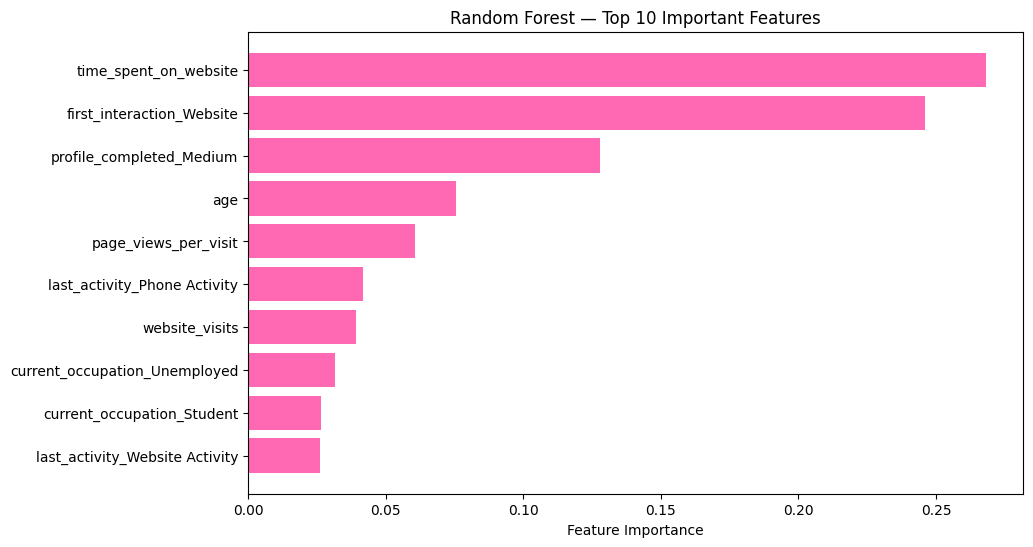

In [155]:
plt.figure(figsize=(10, 6))

plt.barh(
    feature_importance_rf.head(10)["Feature"][::-1],
    feature_importance_rf.head(10)["Importance"][::-1],
    color='hotpink'
)

plt.xlabel("Feature Importance")
plt.title("Random Forest — Top 10 Important Features")
plt.show()

## Final Conclusion and Business Recommendations

This project aimed to identify the factors associated with lead conversion and develop machine learning models to predict which prospective customers are most likely to convert.

### Key Findings

- **Exploratory Data Analysis:** Website engagement, first interaction channel, profile completion, and occupation showed meaningful associations with lead conversion. Leads spending more time on the website and those with more complete profiles generally demonstrated higher conversion rates.
- **Model Performance:** Four classification algorithms were evaluated: Logistic Regression, Decision Tree, Random Forest, and Gradient Boosting. Random Forest achieved the highest test accuracy (**87.32%**), while Gradient Boosting achieved the highest five-fold cross-validation accuracy (**86.15%**) and F1-score (**76.09%**).
- **Recall:** Decision Tree achieved the highest cross-validation recall (**76.74%**), making it particularly useful when identifying as many potential converters as possible is the priority.
- **Hyperparameter Tuning:** GridSearchCV did not improve Decision Tree or Gradient Boosting within the parameter ranges tested. The original configurations remained optimal.
- **Feature Importance:** Random Forest identified three particularly influential predictors:
  1. **Time spent on the website (26.83%)**
  2. **First interaction through the website (24.60%)**
  3. **Medium profile completion (12.78%)**

  Together, these three encoded features accounted for approximately **64% of total feature importance**. These scores measure contributions to the model's predictions, not causal effects or the direction of conversion probability.

### Business Recommendations

1. **Prioritize highly engaged leads:** Time spent on the website was the strongest predictor in Random Forest. Sales teams should consider using website engagement as an important signal when prioritizing follow-up activities.

2. **Consider the first interaction channel:** Website-first interaction was the second most important feature. Our Logistic Regression analysis also associated website-first interactions with higher conversion odds relative to mobile-app-first interactions. This suggests that the initial interaction channel could be valuable in lead prioritization, although it does not establish that changing the channel would increase conversion.

3. **Use profile completion as a lead-scoring indicator:** Profile completion emerged as an important predictive factor. EDA suggested higher conversion rates among leads with more complete profiles, while Random Forest assigned substantial importance to the medium-completion category. Sales teams could incorporate profile completion into lead scoring, rather than assuming that encouraging profile completion itself will cause conversions to increase.

4. **Implement predictive lead scoring:** Gradient Boosting and Random Forest are promising candidates for ranking prospective customers. Decision Tree may be preferable when the business prioritizes recall and wants to minimize missed conversion opportunities.

5. **Monitor model performance:** Evaluate the selected model on new leads and periodically monitor accuracy, precision, recall, and F1-score. Model selection should reflect the relative business costs of missed conversions and unnecessary follow-ups.

### Final Assessment

Our analysis identified **Gradient Boosting and Random Forest as the strongest overall classification candidates**, with Gradient Boosting performing slightly better in cross-validation and Random Forest achieving the highest test accuracy. The differences between the leading models were relatively small, so neither can be declared definitively superior.

For interpretation, we used **Random Forest feature importance**, which highlighted website engagement, initial interaction channel, and profile completion as important predictive signals. These findings were broadly consistent with our exploratory analysis.

**The principal business insight is that lead behavior and engagement provide valuable information for predicting conversion.** By combining these signals with machine learning, ExtraaLearn could develop a more systematic approach to prioritizing prospective customers and allocating sales resources.

Further independent validation would be necessary before deploying a model in a real business environment.